# Step 2: Dataset construction and split

**BT4222 Final Project: Group 13, JDSearch**

Step 1 characterised the temporal horizons of each action type. Step 2 turns the raw log into the four tables every later stage consumes, over a fixed sample of users, and decides the train, validation and test split. It also checks the sample and split distributions to account for bias.

Relevant decisions:
- **Complete histories, not truncated.** The ranker's long-preference profile depends on old orders. Any cap on history length would remove exactly the events Step 1 showed are the only long-horizon signal.
- **Split by user, not by row.** preventing data leakage.
- **A fingerprint of the split.** The partition is hashed and stored alongside the run so it is stable.

One raw row is one search session: a query, a candidate slate with graded outcomes (`0` none, `1` click, `2` cart, `3` purchase), and the preceding history as parallel lists with inter-event gaps.

> Raw row (abridged exmaple): {query = "wireless mouse", candidate_wid_list = [A, B, C, D], candidate_label = [0, 1, 3, 0], history_wid_list = [X, Y, Z], history_type_list = [ORD, CLICK, CART], history_qry_list = ["gaming mouse", "mouse pad", "mouse"], history_time_list = [0, 8000000, 2000000, 500000]}

`history_time_list` holds n+1 gaps for n events, so the age of the order is `(2000000 + 500000) / 86400` days and the age of the cart is `500000 / 86400` days.

Step 2 flattens that row into one row per fact:
> sessions : {session_id=42, query="wireless mouse", slate_size=4, n_hist=3, split="train"}

> candidates : {(42, A, 0) (42, B, 1) (42, C, 3) (42, D, 0)}

> history : {(42, pos=0, wid=X, type="ORD", qry="gaming mouse", elapsed_days=29.1), (42, pos=1, wid=Y, type="CLICK", qry="mouse pad", elapsed_days=17.3), (42, pos=2, wid=Z, type="CART", qry="mouse", elapsed_days=5.8)}

This allows us to:
- **Filter by split.** `history` rows inherit their session's split, so a train session's past events cannot leak into a test session's features.
- **Group by user.** Avoids the need for recomputing ages from raw gaps per step
- **Sample a sequence.** `sort by pos` on `history`, filtered by action type. 

Part A of this notebook rebuilds the tables. Part B reads and verifies the committed tables.


## 0. Environment setup

In [19]:
# Optional: install dependencies in a fresh environment (Colab already has most of them)
# !pip -q install numpy pandas pyarrow scipy scikit-learn lightgbm joblib matplotlib torch

import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/steffanylars/nus-web-mining-business-insights.git"
BRANCH = "main"   # final submission branch
MOUNT_DRIVE = False                    # Colab only: True keeps raw data and outputs on Google Drive
DRIVE_DIR = "/content/drive/MyDrive/JDsearch"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if MOUNT_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        os.environ.setdefault("JD_USER_TXT", f"{DRIVE_DIR}/user_behavior_data.txt")
        os.environ.setdefault("JD_PRODUCT_TXT", f"{DRIVE_DIR}/product_meta_data.txt")
        os.environ.setdefault("JD_RUN_DIR", f"{DRIVE_DIR}/runs/corrected")
    repo = Path("/content/nus-web-mining-business-insights")
    if not (repo / ".git").exists():
        subprocess.run(["git", "clone", "--branch", BRANCH, REPO_URL, str(repo)], check=True)
    PROJECT_ROOT = repo / "Final Project"
else:
    here = Path.cwd()
    options = [here, here.parent, here / "Final Project", here.parent / "Final Project"]
    PROJECT_ROOT = next((p for p in options if (p / "src" / "config.py").exists()), None)
    assert PROJECT_ROOT is not None, "open this notebook from Final Project/ or Final Project/notebooks/"

SRC = PROJECT_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

def _short(p):
    if p is None:
        return "<unset>"
    s = str(p)
    if s.startswith("<"):
        return s
    parts = Path(s).parts
    return str(Path(*parts[-2:])) if len(parts) >= 2 else str(p)

print("project root:", _short(PROJECT_ROOT))
print("run dir     :", _short(os.environ.get("JD_RUN_DIR", "<default: artifacts/corrected>")))

project root: nus-web-mining-business-insights\Final Project
run dir     : <default: artifacts/corrected>


## 1. Imports and shared helpers

The seed used here is the same seed used by every later stage. Any feature-vocabulary, normalisation or sampling decision that depends on the seed is therefore conditioned on the same draw as the sample.

In [20]:
import csv, hashlib, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from config import OUT, RES, SRC_USER, SRC_PRODUCT, SEED, SCHEMA_VERSION, prepare, save_json
from data_utils import split_list, elapsed_days

%matplotlib inline
prepare()
print("seed:", SEED, "| schema version:", SCHEMA_VERSION)

seed: 42 | schema version: 2


### 2. Run switch

Part A is skipped when the run directory already holds a committed run, so the audited evidence is not overwritten by a local re-execution. 

In [23]:
COMMITTED = (PROJECT_ROOT / "artifacts" / "corrected").resolve()
ALLOW_OVERWRITE = IN_COLAB      # a Colab clone is disposable; locally keep the committed evidence safe
HAS_INPUTS = SRC_USER.exists() and SRC_PRODUCT.exists()
RUN_STEP = HAS_INPUTS and (RES.resolve() != COMMITTED or ALLOW_OVERWRITE)

def _short(p):
    if p is None:
        return "<unset>"
    s = str(p)
    if s.startswith("<"):
        return s
    parts = Path(s).parts
    return str(Path(*parts[-2:])) if len(parts) >= 2 else str(p)

print("inputs found    :", HAS_INPUTS)
print("outputs go to   :", _short(RES))
print("RUN_STEP        :", RUN_STEP)
if not RUN_STEP:
    print("Part A is skipped here.")
    print("Part B below shows the measured outputs saved in", _short(RES))

inputs found    : True
outputs go to   : artifacts\corrected
RUN_STEP        : False
Part A is skipped here.
Part B below shows the measured outputs saved in artifacts\corrected


# Part A: Rebuilding the dataset

## A.1 Sample size

The sample is 20,000 users, which is small enough to keep every later stage runnable, but large enough to give the test partition statistical weight.

In [21]:
start = time.time()
n_users = 20000
if n_users < 10:
    raise ValueError('Use at least 10 users for a three-way split')
print("sample size:", n_users)

sample size: 20000


### A.2 Parsing and validation (`build_records`)

This function expands one raw row into the three per-session tables. It rejects lists that disagree in length, action types outside `CLICK`, `CART`, `ORD`, `FLW`, and outcome labels outside `0, 1, 2, 3`.

In [12]:
def build_records(records, selected):
    candidates, histories, sessions = [], [], []
    selected = set(selected)
    sid = 0
    for source_row, row in enumerate(records):
        if source_row not in selected:
            continue
        cw = split_list(row['candidate_wid_list'])
        labs = [int(float(x)) for x in split_list(row['candidate_label_list'])]
        hw = split_list(row['history_wid_list'])
        ht = split_list(row['history_type_list'])
        hq = split_list(row['history_qry_list'])
        if not cw or len(cw) != len(labs) or len(set(cw)) != len(cw):
            raise ValueError(f'Invalid candidate alignment at source row {source_row}')
        if len(hw) != len(ht) or len(hw) != len(hq) or any(x not in {'CLICK','CART','ORD','FLW'} for x in ht):
            raise ValueError(f'Invalid history alignment at source row {source_row}')
        if any(x not in {0,1,2,3} for x in labs):
            raise ValueError(f'Invalid labels at source row {source_row}')
        age = elapsed_days([float(x) for x in split_list(row['history_time_list'])], len(hw))
        candidates.extend((sid,row['query'],w,lab) for w,lab in zip(cw,labs))
        histories.extend((sid,pos,w,t,q,float(d)) for pos,(w,t,q,d) in enumerate(zip(hw,ht,hq,age)))
        sessions.append((sid,source_row,row['query'],len(cw),len(hw)))
        sid += 1
    cand = pd.DataFrame(candidates, columns=['session_id','query','cand_wid','label'])
    hist = pd.DataFrame(histories, columns=['session_id','pos','wid','type','qry','elapsed_days'])
    sess = pd.DataFrame(sessions, columns=['session_id','source_row_id','query','slate_size','n_hist'])
    perm = np.random.default_rng(SEED).permutation(len(sess))
    a = int(.70*len(sess)); b = a + int(.15*len(sess))
    split = np.empty(len(sess), dtype=object)
    split[perm[:a]], split[perm[a:b]], split[perm[b:]] = 'train', 'val', 'test'
    sess['split'] = split
    return cand, hist, sess

### A.3 Drawing the sample

Twenty thousand row indices are drawn from the 173,831 user rows in a single ordered pass.
Check the distribution of the drawn sample to ensure there are no biases: history length (mean 154.56 against 153.41), slate size (mean 89.10 against 89.22) and action-type shares (all within 0.6 percent relative). 

In [31]:
if RUN_STEP:
    with SRC_USER.open('rb') as f:
        n_rows = sum(1 for _ in f) - 1
    idx = np.sort(np.random.default_rng(SEED).choice(n_rows, min(n_rows, n_users), replace=False))
    sample_source_rows = set(idx.tolist())
else:
    committed_sessions_path = OUT / "sessions.parquet"
    committed = pd.read_parquet(committed_sessions_path)
    sample_source_rows = set(committed["source_row_id"].astype(int).tolist())

# Composition check. Runs regardless of RUN_STEP. Reads the raw file once for
# population aggregates and compares against the sample identified above.
types = ['CLICK', 'CART', 'ORD', 'FLW']

pop_hist_lengths = []
pop_slate_sizes = []
pop_type_counts = {t: 0 for t in types}

samp_hist_lengths = []
samp_slate_sizes = []
samp_type_counts = {t: 0 for t in types}

pop_n_users = 0
samp_n_users = 0

with SRC_USER.open(encoding='utf-8', newline='') as f:
    reader = csv.DictReader(f, delimiter='\t')
    for i, row in enumerate(reader):
        htypes = split_list(row.get('history_type_list'))
        hlen = len(htypes)
        clen = len(split_list(row.get('candidate_wid_list')))

        pop_n_users += 1
        pop_hist_lengths.append(hlen)
        pop_slate_sizes.append(clen)
        for t in htypes:
            if t in pop_type_counts:
                pop_type_counts[t] += 1

        if i in sample_source_rows:
            samp_n_users += 1
            samp_hist_lengths.append(hlen)
            samp_slate_sizes.append(clen)
            for t in htypes:
                if t in samp_type_counts:
                    samp_type_counts[t] += 1

pop_hist_total = sum(pop_type_counts.values())
samp_hist_total = sum(samp_type_counts.values())

print(f"population users: {pop_n_users:,}   sampled users: {samp_n_users:,}")
print()
print("History length per user")
print(f"  population mean {np.mean(pop_hist_lengths):8.2f}   median {np.median(pop_hist_lengths):7.1f}   share <=2 {np.mean(np.array(pop_hist_lengths) <= 2):.4f}")
print(f"  sample     mean {np.mean(samp_hist_lengths):8.2f}   median {np.median(samp_hist_lengths):7.1f}   share <=2 {np.mean(np.array(samp_hist_lengths) <= 2):.4f}")
print()
print("Slate size per user")
print(f"  population mean {np.mean(pop_slate_sizes):8.2f}   median {np.median(pop_slate_sizes):7.1f}")
print(f"  sample     mean {np.mean(samp_slate_sizes):8.2f}   median {np.median(samp_slate_sizes):7.1f}")
print()
print("Action-type composition (share of history events)")
print(f"  population total events: {pop_hist_total:,}")
for t in types:
    print(f"    {t:5s} {pop_type_counts[t] / max(pop_hist_total, 1):.4f}")
print(f"  sample total events: {samp_hist_total:,}")
for t in types:
    print(f"    {t:5s} {samp_type_counts[t] / max(samp_hist_total, 1):.4f}")

population users: 173,831   sampled users: 20,000

History length per user
  population mean   153.41   median    78.0   share <=2 0.0234
  sample     mean   154.56   median    78.0   share <=2 0.0230

Slate size per user
  population mean    89.22   median    90.0
  sample     mean    89.10   median    90.0

Action-type composition (share of history events)
  population total events: 26,667,260
    CLICK 0.3112
    CART  0.4322
    ORD   0.2556
    FLW   0.0009
  sample total events: 3,091,153
    CLICK 0.3099
    CART  0.4347
    ORD   0.2542
    FLW   0.0012


### A.4 Build the session tables

Each sampled session is expanded into one row per candidate, one row per preceding event, one row per session. Every preceding event is kept, ensuring the long-preference profile uses orders of any age.

In [25]:
if RUN_STEP:
    with SRC_USER.open(encoding='utf-8', newline='') as f:
        cand,hist,sess = build_records(csv.DictReader(f, delimiter='\t'), idx.tolist())
    print(f'Built {len(sess):,} users; {len(hist):,} complete history events', flush=True)

### A.5 Product metadata

The raw product file is read once and filtered to the products referenced by any candidate or any history event. The content features are informed by the product metadata (category name, brand name, etc.)

In [26]:
if RUN_STEP:
    refs = set(cand.cand_wid) | set(hist.wid)
    metadata = []
    with SRC_PRODUCT.open('rb') as f:
        headers = next(f).decode('utf-8').rstrip('\r\n').split('\t')
        for line in f:
            wid = line.split(b'\t',1)[0].decode('utf-8')
            if wid in refs:
                fields = line.decode('utf-8').rstrip('\r\n').split('\t')
                if len(fields) != len(headers):
                    raise ValueError(f'Invalid metadata alignment for {wid}')
                metadata.append(fields)
    meta = pd.DataFrame(metadata, columns=headers).drop_duplicates('wid')
    if not {'cate_name_3','brand_name','name'}.issubset(meta.columns):
        raise ValueError('Raw metadata requires names as well as IDs')

### A.6 Save tables and run record

Four data tables are saved, plus a run record that stores the parameters of this run: seed, row counts, split sizes, a fingerprint of the split, metadata coverage and raw file sizes.

In [16]:
if RUN_STEP:
    for name,frame in [('candidates',cand),('history',hist),('sessions',sess),('meta_subset',meta)]:
        frame.to_parquet(OUT/f'{name}.parquet', index=False)
    # CRLF is fixed on purpose: pandas would otherwise use the OS line ending and the hash would differ by platform.
    membership = sess[['session_id','source_row_id','split']].to_csv(index=False, lineterminator='\r\n')
    save_json(RES/'dataset_manifest.json', dict(schema_version=SCHEMA_VERSION, seed=SEED,
        source_users=n_rows, sampled_users=len(sess), candidate_rows=len(cand), history_rows=len(hist),
        history_policy='all preceding events; independent horizon selection occurs in neural packing',
        split_counts=sess.groupby('split').size().to_dict(),
        split_sha256=hashlib.sha256(membership.encode()).hexdigest(),
        candidate_metadata_coverage=float(cand.cand_wid.isin(set(meta.wid)).mean()),
        raw_files={p.name: {'bytes':p.stat().st_size} for p in [SRC_USER,SRC_PRODUCT]}))
    print(f'Dataset ready in {OUT} ({time.time()-start:.0f}s)', flush=True)

# Part B: Verifying Constructed Dataset

### B.1 Audit Summary

In [27]:
manifest = json.loads((RES / "dataset_manifest.json").read_text(encoding="utf-8"))
scalars = {k: v for k, v in manifest.items() if not isinstance(v, (dict, list))}
display(pd.Series(scalars, name="value").to_frame())
print("split sizes (sessions):", manifest["split_counts"])
display(pd.DataFrame(manifest["raw_files"]).T.rename(columns={"bytes": "raw file size (bytes)"}))

,value
schema_version,2
seed,42
source_users,173831
sampled_users,20000
candidate_rows,1781978
history_rows,3091153
history_policy,all preceding events; independent horizon sele...
split_sha256,012cd704c2665e7b807934f5f39da79a479ab427a083d9...
candidate_metadata_coverage,0.995498


split sizes (sessions): {'test': 3000, 'train': 14000, 'val': 3000}


,raw file size (bytes)
user_behavior_data.txt,957229589
product_meta_data.txt,4841695274


### B.2 Verify Split and Session Distributions

- Fingerprint match: confirms the split later stages train on is constant.
- Slate size ~90: Evaluation ranks the full slate, measuring ordering quality, not top-k selection.
- History length is heavy-tailed: Most sessions have dozens to a few hundred events. 
- 2,965 of 3,000 test sessions have at least one positive: 35 all-negative sessions are excluded because they have no defined ranking utility.
- Each split matches the sample within about 3 percent relative on the same quantities, reflecting negligible representation bias.

recomputed split fingerprint: 012cd704c2665e7b807934f5f39da79a479ab427a083d913765d618c9308f35c
matches manifest            : True
shares by split             : {'train': 0.7, 'val': 0.15, 'test': 0.15}


,slate_size,n_hist
count,20000.0,20000.0
mean,89.1,154.6
std,38.6,230.0
min,1.0,1.0
25%,77.0,28.0
50%,90.0,78.0
75%,94.2,189.0
max,200.0,4719.0


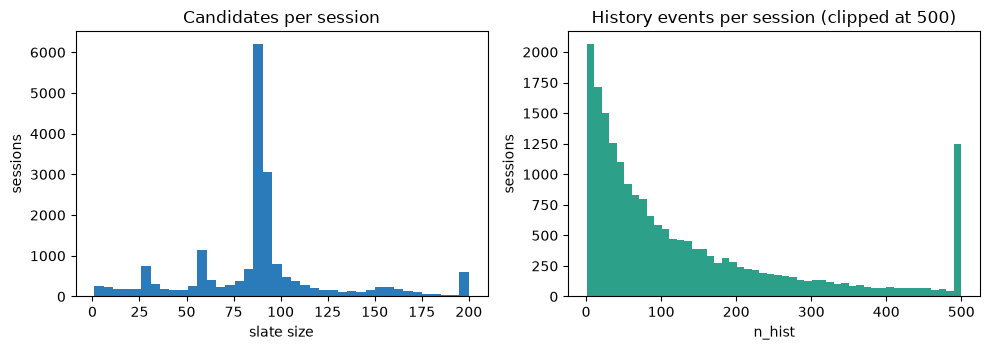

sessions with n_hist == 0: 0 | n_hist <= 2: 459


,group,n_sessions,mean hist len,median hist len,share n_hist <=2,mean slate,CLICK share,CART share,ORD share
0,sample (all),20000,154.56,78.0,0.0230,89.10,0.3102,0.4352,0.2545
1,train,14000,155.88,79.0,0.0213,89.26,0.3070,0.4385,0.2545
2,val,3000,151.88,76.0,0.0327,88.59,0.3167,0.4265,0.2568
3,test,3000,151.07,78.0,0.0210,88.88,0.3195,0.4284,0.2521


In [35]:
sess_saved = pd.read_parquet(OUT / "sessions.parquet")

# same recipe as A.6, including the fixed CRLF line ending, so the hash is identical on every OS
membership = sess_saved[["session_id", "source_row_id", "split"]].to_csv(index=False, lineterminator="\r\n")
digest = hashlib.sha256(membership.encode()).hexdigest()
print("recomputed split fingerprint:", digest)
print("matches manifest            :", digest == manifest["split_sha256"])
print("shares by split             :", (sess_saved.split.value_counts(normalize=True).round(3)).to_dict())

display(sess_saved[["slate_size", "n_hist"]].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(sess_saved.slate_size, bins=40, color="#2b7bba")
axes[0].set(title="Candidates per session", xlabel="slate size", ylabel="sessions")
axes[1].hist(sess_saved.n_hist.clip(upper=500), bins=50, color="#2ca089")
axes[1].set(title="History events per session (clipped at 500)", xlabel="n_hist", ylabel="sessions")
plt.tight_layout()
plt.show()
print("sessions with n_hist == 0:", int((sess_saved.n_hist == 0).sum()),
      "| n_hist <= 2:", int((sess_saved.n_hist <= 2).sum()))

# Split-level composition check. The action-type shares per split are not
# recoverable from sessions.parquet alone, so the raw file is read once more
# but only the 20,000 sampled rows are parsed.
types_b = ["CLICK", "CART", "ORD"]
split_by_source_row = dict(zip(sess_saved["source_row_id"].astype(int),
                               sess_saved["split"]))

split_type_counts = {s: {t: 0 for t in types_b} for s in ("train", "val", "test")}
split_hist_lengths = {s: [] for s in ("train", "val", "test")}
split_slate_sizes  = {s: [] for s in ("train", "val", "test")}

with SRC_USER.open(encoding='utf-8', newline='') as f:
    reader = csv.DictReader(f, delimiter='\t')
    for i, row in enumerate(reader):
        if i not in split_by_source_row:
            continue
        s = split_by_source_row[i]
        htypes = split_list(row.get('history_type_list'))
        split_hist_lengths[s].append(len(htypes))
        split_slate_sizes[s].append(len(split_list(row.get('candidate_wid_list'))))
        for t in htypes:
            if t in split_type_counts[s]:
                split_type_counts[s][t] += 1

def _row(label, sessions_frame, hist_lengths, slate_sizes, type_counts):
    hlen = np.asarray(hist_lengths)
    total = sum(type_counts.values())
    row = {
        "group": label,
        "n_sessions": len(sessions_frame),
        "mean hist len": round(float(hlen.mean()), 2),
        "median hist len": float(np.median(hlen)),
        "share n_hist <=2": round(float((hlen <= 2).mean()), 4),
        "mean slate": round(float(np.mean(slate_sizes)), 2),
    }
    for t in types_b:
        row[f"{t} share"] = round(type_counts.get(t, 0) / max(total, 1), 4)
    return row

all_hist_lengths = sum((split_hist_lengths[s] for s in split_hist_lengths), [])
all_slate_sizes  = sum((split_slate_sizes[s]  for s in split_slate_sizes),  [])
all_type_counts  = {t: sum(split_type_counts[s][t] for s in split_type_counts) for t in types_b}

composition_rows = [
    _row("sample (all)", sess_saved,
         all_hist_lengths, all_slate_sizes, all_type_counts),
    _row("train", sess_saved[sess_saved.split == "train"],
         split_hist_lengths["train"], split_slate_sizes["train"], split_type_counts["train"]),
    _row("val", sess_saved[sess_saved.split == "val"],
         split_hist_lengths["val"], split_slate_sizes["val"], split_type_counts["val"]),
    _row("test", sess_saved[sess_saved.split == "test"],
         split_hist_lengths["test"], split_slate_sizes["test"], split_type_counts["test"]),
]
display(pd.DataFrame(composition_rows))

## Summary

| Finding | Value |
|---|---|
| Sample size | 20,000 users |
| Sampled candidate pairs | 1,781,978 |
| Sampled historical events | 3,091,153 |
| Sample matches population | History length mean 154.56 against 153.41; slate size 89.10 against 89.22; action-type shares within 0.6 percent relative |
| Split matches sample | Within 3 percent relative on all three quantities; validation short-history 3.27 against 2.30 percent (three sessions) |
| Test sessions with at least one positive | 2,965 of 3,000 |
| Sessions with zero history events | 0 |
| Sessions with two or fewer history events | 459 |

## Appendix: artefacts

| Artefact | Content |
|---|---|
| `candidates.parquet` | One row per session and candidate, with outcome label |
| `history.parquet` | One row per session and preceding event, with action type, past query and age in days |
| `sessions.parquet` | One row per session, with split membership and history length |
| `meta_subset.parquet` | One row per referenced product, with the five metadata columns the ranker reads |
| `dataset_manifest.json` | Seed, counts, split fingerprint, metadata coverage, raw file sizes |
